# Exercise 1.4: campaign decisions

**Marketing campaigns** · `data/creadores.csv`

This notebook puts the results of 1.1 (PCA), 1.2 (Kohonen) and 1.3 (Oja) side by side and turns them
into creator selections for the four clients. The cells only compute and plot; the decisions are left
in the Decision blocks at the end of each section.

**Requires** `results/kohonen_models/som_tuned.npz`. Generate it from the project root with
`python -m tp4.kohonen.run_kohonen_tuning`. Different machines can produce a different map, so
re-run this notebook after the sweep before quoting numbers.

Selection logic lives in `src/tp4/decisions.py`:
1. Each SOM neuron is labelled with the topic its weights lean towards (its **region**).
2. A client's candidates are the creators whose BMU is in that client's region.
3. Candidates are ranked by one **strategy** score (reach, discovery or depth).
4. Every selection is compared with the agency's current rule (top creators by `followers`) and with the Oja index.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path.cwd().resolve()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.tp4.data import load_creators, standardise
from src.tp4.decisions import (
    CLIENT_TOPICS, STRATEGIES, assign_new_creators, compare_strategies, creator_table, select_mix,
    load_som, neuron_profiles, neuron_topics, region_purity, select_by_strategy,
)
from src.tp4.kohonen.kohonen import Kohonen
from src.tp4.kohonen.metrics import bmu_assignments
from src.tp4.linear.oja import creator_index, fit_oja
from src.tp4.linear.pca import fit_pca

pd.set_option("display.max_colwidth", 120)
K = 5   # creators per campaign

data_path = project_dir / "data" / "creadores.csv"
raw = pd.read_csv(data_path)
df = load_creators(data_path)
X, scaler = standardise(df)

som = load_som(project_dir / "results" / "kohonen_models" / "som_tuned.npz")
assert som["feature_names"] == df.columns.tolist(), "SOM was trained on different variables"
assert np.allclose(som["scaler_mean"], scaler.mean_), "SOM was trained with a different scaling"

creators = creator_table(raw, som, X)
print(f"{len(creators)} creators, map {som['weights'].shape[0]} x {som['weights'].shape[1]}")

50 creators, map 6 x 6


## 1. Strategy definitions

The statement's football question names three strategies: *alcance masivo* (mass reach),
*descubrimiento* (discovery) and *profundidad educativa* (educational depth). Each one is scored as
the mean z-score of the variables below. `followers` is deliberately in none of them, because it is
the baseline.

These variable choices are an **assumption** the report has to justify (the statement allows
assumptions about the features).

In [2]:
pd.DataFrame({s: ", ".join(f) for s, f in STRATEGIES.items()}, index=["variables"]).T

,variables
reach,"average_reach, average_impressions, estimated_argentina_reach"
discovery,"non_follower_reach_pct, shares_per_1000, trend_posts_pct"
depth,"content_tutorial_pct, saves_per_1000, comments_per_1000, profile_visits_per_1000, average_watch_time_seconds"


In [3]:
# How much each strategy is just "size": correlation with PC1 and with log(followers)
pca = fit_pca(X)
pc1 = pca.transform(X)[:, 0]
pd.DataFrame({
    "corr_with_PC1": [np.corrcoef(creators[s], pc1)[0, 1] for s in STRATEGIES],
    "corr_with_log_followers": [np.corrcoef(creators[s], np.log(raw["followers"]))[0, 1] for s in STRATEGIES],
}, index=list(STRATEGIES)).round(2)

,corr_with_PC1,corr_with_log_followers
reach,-0.90,0.80
discovery,-0.86,0.73
depth,0.94,-0.88


## 2. Can SOM regions be used as client segments?

Rows: the region each creator's BMU belongs to. Columns: the creator's own main topic (largest
`topic_*_pct`). A mostly diagonal table means a region groups the creators a client is looking for.

In [4]:
purity = region_purity(creators)
display(purity)
print(f"Creators in the region of their own main topic: {np.trace(purity.to_numpy())} / {len(creators)}")
print("Neurons per region:", neuron_topics(neuron_profiles(som)).value_counts().to_dict())

main_topic,topic_art_pct,topic_dogs_pct,topic_football_pct,topic_makeup_pct
region,,,,
topic_art_pct,10,1,2,0
topic_dogs_pct,0,9,0,0
topic_football_pct,1,3,13,2
topic_makeup_pct,0,0,0,9


Creators in the region of their own main topic: 41 / 50
Neurons per region: {'topic_football_pct': 10, 'topic_makeup_pct': 9, 'topic_art_pct': 9, 'topic_dogs_pct': 8}


In [5]:
# Creators that the SOM places outside their own topic's region
off = creators[creators["region"] != creators["main_topic"]]
off_profile = raw.loc[off.index, ["name", "followers", *CLIENT_TOPICS.values()]]
off_profile.assign(region=off["region"], main_topic=off["main_topic"])

,name,followers,topic_dogs_pct,topic_football_pct,topic_makeup_pct,topic_art_pct,region,main_topic
6,@patitasenred,198816,62.57,12.18,12.53,12.72,topic_football_pct,topic_dogs_pct
13,@brochasycolor,86015,9.39,11.72,66.62,12.27,topic_football_pct,topic_makeup_pct
19,@manosalaobra,112959,9.37,69.34,10.62,10.67,topic_art_pct,topic_football_pct
24,@reelargentino,18000,15.53,13.56,59.62,11.29,topic_football_pct,topic_makeup_pct
27,@ideasconhuella,34822,55.60,14.05,13.35,17.00,topic_football_pct,topic_dogs_pct
35,@crearenreels,551553,66.99,14.86,9.93,8.22,topic_football_pct,topic_dogs_pct
39,@galeriacotidiana,381324,13.58,11.81,13.57,61.04,topic_football_pct,topic_art_pct
46,@patitascontentas,72459,68.57,6.79,10.43,14.21,topic_art_pct,topic_dogs_pct
49,@reelconideas,16905,18.94,45.58,11.60,23.88,topic_art_pct,topic_football_pct


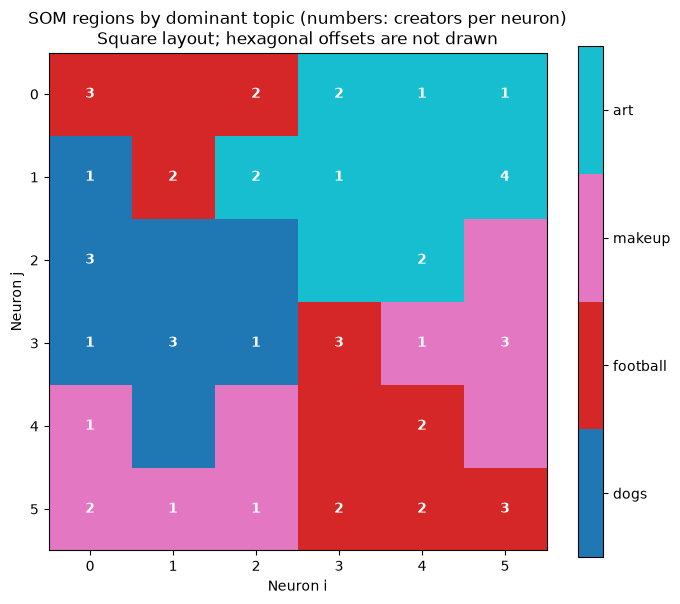

In [6]:
regions = neuron_topics(neuron_profiles(som))
width, height = som["weights"].shape[:2]
topic_ids = {t: k for k, t in enumerate(CLIENT_TOPICS.values())}
grid = np.array([[topic_ids[regions.loc[(i, j)]] for j in range(height)] for i in range(width)])

fig, ax = plt.subplots(figsize=(7, 6))
cmap = plt.get_cmap("tab10", len(topic_ids))
im = ax.imshow(grid.T, cmap=cmap, vmin=-0.5, vmax=len(topic_ids) - 0.5, origin="upper")
for i in range(width):
    for j in range(height):
        n = som["bmu_counts"][i, j]
        if n:
            ax.text(i, j, n, ha="center", va="center", color="white", fontweight="bold")
cbar = fig.colorbar(im, ticks=range(len(topic_ids)))
cbar.ax.set_yticklabels([t.replace("topic_", "").replace("_pct", "") for t in topic_ids])
ax.set_title("SOM regions by dominant topic (numbers: creators per neuron)\n"
             "Square layout; hexagonal offsets are not drawn")
ax.set_xlabel("Neuron i")
ax.set_ylabel("Neuron j")
plt.tight_layout()
plt.show()

### Robustness of the regions

The regions come from one trained map. Retraining with the same configuration and other seeds shows
how much of the segmentation depends on the seed.

In [7]:
import json
config = json.loads((project_dir / "results" / "kohonen_models" / "som_tuned.json").read_text())

rows = []
for seed in range(5):
    m = Kohonen(X, config["map_size"], config["map_size"], config["n_iterations"],
                config["learning_rate"], config["initial_radius"],
                config["n_iterations"] / np.log(config["initial_radius"]),
                np.random.default_rng(seed), grid_type=config["grid_type"])
    m.create_map()
    bmu, _ = bmu_assignments(m, X)
    alt = {**som, "weights": m.weights, "bmu_indices": bmu}
    alt_creators = creator_table(raw, alt, X)
    rows.append({
        "seed": seed,
        "in_own_topic_region": int((alt_creators["region"] == alt_creators["main_topic"]).sum()),
        **{f"{c}_top{K}_reach": ", ".join(raw.loc[select_by_strategy(alt_creators, c, "reach", K), "name"])
           for c in ["football_apparel"]},
    })
pd.DataFrame(rows)

,seed,in_own_topic_region,football_apparel_top5_reach
0,0,38,"@golconmate, @futbolsinvueltas, @tribunacreativa, @tacticavisual, @makeupconsejos"
1,1,41,"@golconmate, @futbolsinvueltas, @tribunacreativa, @tacticavisual, @makeupconsejos"
2,2,43,"@golconmate, @futbolsinvueltas, @tribunacreativa, @tacticavisual, @makeupconsejos"
3,3,37,"@golconmate, @futbolsinvueltas, @tribunacreativa, @tacticavisual, @makeupconsejos"
4,4,40,"@golconmate, @futbolsinvueltas, @tribunacreativa, @tacticavisual, @makeupconsejos"


## 3. Selections per client

For every client: the SOM region ranked by each strategy, the followers-only rule and the Oja index
(top-5 overall).

Columns:
- `on_topic`: share of the selected creators whose main topic is the client's topic.
- `mean_topic_pct`: average share of their posts on the client's topic.
- `total_price_usd` / `total_argentina_reach`: one sponsored post per creator.
- `on_topic_arg_reach_per_usd`: Argentine reach weighted by on-topic share, per dollar.
- `mean_reach` / `mean_discovery` / `mean_depth`: strategy scores (z-scores, 0 = average creator).

In [8]:
w, _ = fit_oja(X)
if w @ pca.components_[0] < 0:
    w = -w
oja = creator_index(X, w)

comparisons = {client: compare_strategies(raw, creators, client, K, oja_index=oja)
               for client in CLIENT_TOPICS}
numeric = ["on_topic", "mean_topic_pct", "total_price_usd", "total_argentina_reach",
           "on_topic_arg_reach_per_usd", "mean_reach", "mean_discovery", "mean_depth"]
for client, table in comparisons.items():
    print(f"\n=== {client} ({CLIENT_TOPICS[client]}) ===")
    display(table[numeric].astype(float).round(2))


=== dog_shelter (topic_dogs_pct) ===


,on_topic,mean_topic_pct,total_price_usd,total_argentina_reach,on_topic_arg_reach_per_usd,mean_reach,mean_discovery,mean_depth
som_reach,1.0,70.88,2096.72,43964.0,14.95,-0.75,-0.67,0.45
som_discovery,1.0,70.49,1752.77,42693.0,17.31,-0.75,-0.45,0.52
som_depth,1.0,72.05,956.10,20459.0,15.15,-0.86,-1.30,1.13
som_mix,1.0,71.84,642.71,19332.0,21.20,-0.85,-1.16,1.12
followers_only,0.2,21.32,22657.12,881361.0,9.64,2.10,0.77,-1.15
oja_index,1.0,69.41,876.90,17239.0,13.64,-0.87,-1.50,1.24



=== football_apparel (topic_football_pct) ===


,on_topic,mean_topic_pct,total_price_usd,total_argentina_reach,on_topic_arg_reach_per_usd,mean_reach,mean_discovery,mean_depth
som_reach,1.0,69.41,20741.98,468916.0,16.41,1.19,1.04,-1.04
som_discovery,1.0,66.83,20035.11,337427.0,11.10,0.78,1.06,-0.93
som_depth,1.0,57.92,2333.63,50791.0,13.55,-0.69,-0.44,0.64
som_mix,1.0,68.58,5478.62,186500.0,24.53,-0.29,-0.05,0.33
followers_only,0.2,26.94,22657.12,881361.0,11.51,2.10,0.77,-1.15
oja_index,0.0,8.73,876.90,17239.0,1.70,-0.87,-1.50,1.24



=== beauty (topic_makeup_pct) ===


,on_topic,mean_topic_pct,total_price_usd,total_argentina_reach,on_topic_arg_reach_per_usd,mean_reach,mean_discovery,mean_depth
som_reach,1.0,70.14,21298.57,519126.0,16.22,1.32,0.51,-1.06
som_discovery,1.0,64.14,19411.74,511821.0,17.18,1.21,0.76,-0.95
som_depth,1.0,67.68,7655.84,160992.0,14.16,-0.06,0.32,-0.19
som_mix,1.0,67.68,7655.84,160992.0,14.16,-0.06,0.32,-0.19
followers_only,0.6,42.91,22657.12,881361.0,14.16,2.10,0.77,-1.15
oja_index,0.0,11.08,876.90,17239.0,2.23,-0.87,-1.50,1.24



=== art_supplies (topic_art_pct) ===


,on_topic,mean_topic_pct,total_price_usd,total_argentina_reach,on_topic_arg_reach_per_usd,mean_reach,mean_discovery,mean_depth
som_reach,1.0,63.79,8754.50,173967.0,13.20,0.01,0.40,-0.31
som_discovery,1.0,63.44,6827.87,128885.0,12.25,-0.23,0.50,-0.13
som_depth,1.0,59.51,3779.72,61019.0,9.89,-0.57,-0.25,0.24
som_mix,1.0,59.99,4371.93,96796.0,13.26,-0.46,-0.25,0.14
followers_only,0.0,8.83,22657.12,881361.0,3.59,2.10,0.77,-1.15
oja_index,0.0,10.78,876.90,17239.0,2.09,-0.87,-1.50,1.24


In [9]:
# Who is selected (names) per client and rule
pd.concat({c: t["creators"] for c, t in comparisons.items()}).to_frame("creators")

creators
dog_shelter      som_reach       @huellasargentinas, @adoptafelicidad, @estiloydetalle, @clubdelasmascotas, @perrosfelices.ar
                 som_discovery      @huellasargentinas, @guiadehuellas, @estiloydetalle, @adoptafelicidad, @clubdelasmascotas
                 som_depth            @mundoanimal.ar, @consejoscaninos, @guiadehuellas, @huellasyconsejos, @perrosfelices.ar
                 som_mix                @guiadehuellas, @estiloydetalle, @mundoanimal.ar, @consejoscaninos, @huellasyconsejos
                 followers_only                     @mateconideas, @golconmate, @brillourbano, @maquillajereal, @crearenreels
                 oja_index           @mundoanimal.ar, @consejoscaninos, @huellasyconsejos, @ideasconhuella, @perrosfelices.ar
football_apparel som_reach                  @golconmate, @futbolsinvueltas, @tribunacreativa, @tacticavisual, @makeupconsejos
                 som_discovery            @makeupconsejos, @futbolsinvueltas, @tribunacreativa, @lookdecancha, @tacticavisual
                 som_depth                @futbolentrepases, @pasionalbirroja, @pasiondepotrero, @canchaaldia, @jugadayestilo
                 som_mix                   @lookdecancha, @jugadayestilo, @futbolcononda, @futbolentrepases, @pasionalbirroja
                 followers_only                     @mateconideas, @golconmate, @brillourbano, @maquillajereal, @crearenreels
                 oja_index           @mundoanimal.ar, @consejoscaninos, @huellasyconsejos, @ideasconhuella, @perrosfelices.ar
beauty           som_reach                         @mateconideas, @maquillajereal, @brillourbano, @glamencasa, @bellezasimple
                 som_discovery                      @tallerurbano, @brillourbano, @maquillajereal, @mateconideas, @glamencasa
                 som_depth             @brochasymates, @cosmeticaconsciente, @tallerurbano, @brilloytendencia, @bellezasimple
                 som_mix               @tallerurbano, @brochasymates, @bellezasimple, @cosmeticaconsciente, @brilloytendencia
                 followers_only                     @mateconideas, @golconmate, @brillourbano, @maquillajereal, @crearenreels
                 oja_index           @mundoanimal.ar, @consejoscaninos, @huellasyconsejos, @ideasconhuella, @perrosfelices.ar
art_supplies     som_reach                     @artequeinspira, @pincelcotidiano, @rinconcreativo, @artealpaso, @entrelienzos
                 som_discovery              @entrelienzos, @pincelcotidiano, @colorenmovimiento, @artealpaso, @rinconcreativo
                 som_depth                 @colorenmovimiento, @creatividadaldia, @trazosyreels, @arteentusmanos, @artealpaso
                 som_mix                  @colorenmovimiento, @rinconcreativo, @canvasycafe, @creatividadaldia, @trazosyreels
                 followers_only                     @mateconideas, @golconmate, @brillourbano, @maquillajereal, @crearenreels
                 oja_index           @mundoanimal.ar, @consejoscaninos, @huellasyconsejos, @ideasconhuella, @perrosfelices.ar

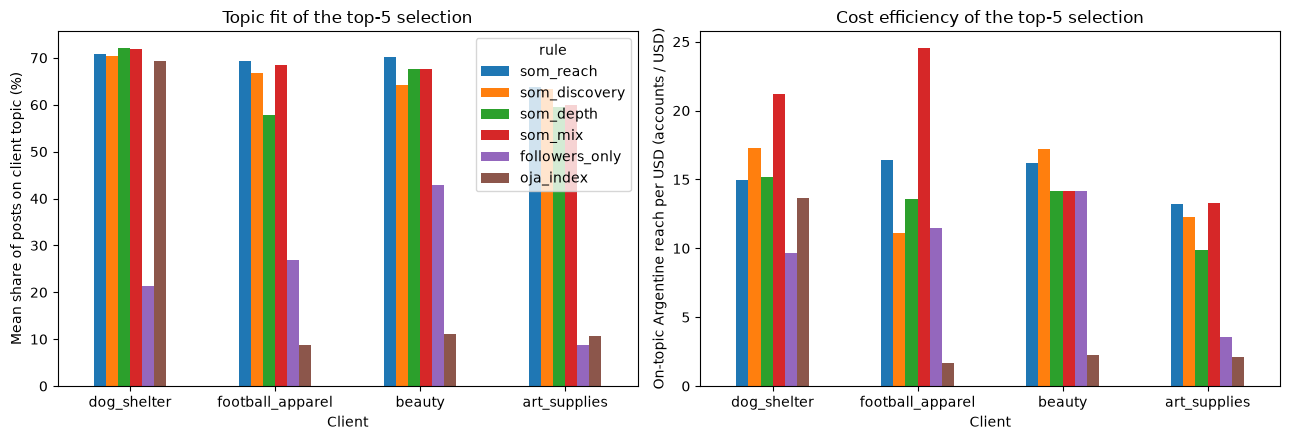

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
summary = pd.concat({c: t[numeric].astype(float) for c, t in comparisons.items()}, names=["client", "rule"])
summary["mean_topic_pct"].unstack("rule").plot.bar(ax=axes[0], rot=0)
axes[0].set_ylabel("Mean share of posts on client topic (%)")
axes[0].set_title(f"Topic fit of the top-{K} selection")
summary["on_topic_arg_reach_per_usd"].unstack("rule").plot.bar(ax=axes[1], rot=0, legend=False)
axes[1].set_ylabel("On-topic Argentine reach per USD (accounts / USD)")
axes[1].set_title(f"Cost efficiency of the top-{K} selection")
for ax in axes:
    ax.set_xlabel("Client")
plt.tight_layout()
plt.show()

## 4. Football: mass reach, discovery or educational depth?

The football row of section 3 plus the profile of the football region below.

> **Decision:** neither pure mass reach nor pure depth. Use **mid-size discovery creators plus a few depth creators** (`select_mix`): the 3 best discovery scores among football creators priced at or below the median, then the 2 best depth scores.
>
> - Football creators have the highest non-follower reach of any topic (median 67 % vs 49–56 %), so discovery is what this topic does well.
> - Mass reach is what the agency already does: the reach top-5 costs about 20.7k USD, close to the followers-only 22.7k USD, the strategy that did not pay back.
> - Depth creators (tutorials, saves, profile visits) are cheap and show purchase intent, but each reaches only 3–14k Argentines, so on their own they cannot carry a sales campaign.
> - The mix costs about 5.5k USD and gets about 2.1x the on-topic Argentine reach per dollar of followers-only, with 2.5x the saves per 1000 reached.

In [11]:
football = creators[creators["region"] == CLIENT_TOPICS["football_apparel"]]
cols = ["followers", "average_reach", "estimated_argentina_reach", "non_follower_reach_pct",
        "shares_per_1000", "trend_posts_pct", "content_tutorial_pct", "saves_per_1000",
        "comments_per_1000", "average_watch_time_seconds", "price_usd", "topic_football_pct"]
profile = raw.loc[football.index, ["name", *cols]].assign(**football[list(STRATEGIES)].round(2))
profile.sort_values("followers", ascending=False)

,name,followers,average_reach,estimated_argentina_reach,non_follower_reach_pct,shares_per_1000,trend_posts_pct,content_tutorial_pct,saves_per_1000,comments_per_1000,average_watch_time_seconds,price_usd,topic_football_pct,reach,discovery,depth
20,@golconmate,745025,268518,207994,59.70,12.71,53.01,12.94,5.90,3.78,6.00,3251.20,82.18,2.42,0.73,-1.23
35,@crearenreels,551553,263885,233828,76.29,12.26,61.45,22.70,8.45,3.49,10.67,3813.64,14.86,2.53,1.23,-0.82
44,@futbolsinvueltas,493194,216193,58761,72.58,11.57,57.88,0.46,5.16,1.90,11.73,4655.31,63.36,1.34,1.02,-1.34
4,@tribunacreativa,461892,178805,122124,82.10,10.39,54.03,8.25,9.96,3.36,20.94,2806.20,61.10,1.14,1.02,-0.76
39,@galeriacotidiana,381324,222510,186931,78.03,18.73,59.13,0.77,9.42,3.81,28.25,4866.57,11.81,2.11,1.67,-0.71
10,@vidaperruna,374949,128955,36959,76.21,8.36,55.88,8.69,10.86,2.35,18.25,3300.62,69.50,0.41,0.81,-0.96
16,@tacticavisual,349287,155568,45924,71.52,10.90,53.38,10.06,11.40,4.13,13.87,5334.65,81.31,0.55,0.84,-1.03
29,@lookdecancha,270334,98386,76505,81.96,10.18,47.73,2.24,11.98,3.09,19.06,2544.33,69.29,0.36,0.84,-0.66
33,@makeupconsejos,234076,145783,34113,81.61,14.95,64.42,5.88,9.52,4.11,21.28,4694.62,59.10,0.50,1.60,-0.86
6,@patitasenred,198816,122572,73310,58.20,5.41,42.23,16.99,10.34,3.19,18.87,2574.28,12.18,0.50,-0.09,-0.55


In [12]:
# Football creators the region misses (SOM placed them elsewhere)
missed = creators[(creators["main_topic"] == CLIENT_TOPICS["football_apparel"])
                  & (creators["region"] != CLIENT_TOPICS["football_apparel"])]
raw.loc[missed.index, ["name", *cols]].assign(region=missed["region"])

,name,followers,average_reach,estimated_argentina_reach,non_follower_reach_pct,shares_per_1000,trend_posts_pct,content_tutorial_pct,saves_per_1000,comments_per_1000,average_watch_time_seconds,price_usd,topic_football_pct,region
19,@manosalaobra,112959,50907,21187,24.64,4.63,30.21,36.29,14.44,5.33,20.44,1180.23,69.34,topic_art_pct
49,@reelconideas,16905,5082,1746,55.23,13.08,44.52,48.21,18.15,7.20,29.97,100.55,45.58,topic_art_pct


## 5. Comparison with the followers-only strategy

The `followers_only` rows in section 3 are the same five creators for every client, because that rule
ignores the client.

> **Decision:** select by region and campaign goal, not by followers.
>
> - **Followers-only** maximises raw reach (about 880k Argentine accounts for five posts) but picks the same five creators for every client: 1 of 5 on topic for the dog shelter and football, 0 of 5 for art, at 22.7k USD. Most of that reach is not the client's audience.
> - **Region + goal** keeps 5 of 5 on topic for every client and is cheaper, at the cost of lower total reach. It depends on a trained map and on assumptions about which variables define each goal.

In [13]:
top_followers = raw.nlargest(K, "followers")
top_followers[["name", "followers", "price_usd", *CLIENT_TOPICS.values()]].assign(
    region=creators.loc[top_followers.index, "region"])

,name,followers,price_usd,topic_dogs_pct,topic_football_pct,topic_makeup_pct,topic_art_pct,region
0,@mateconideas,775589,6310.69,13.23,9.89,61.58,15.30,topic_makeup_pct
20,@golconmate,745025,3251.20,4.16,82.18,5.89,7.77,topic_football_pct
1,@brillourbano,638718,6334.71,11.04,11.60,70.43,6.93,topic_makeup_pct
9,@maquillajereal,608003,2946.88,11.16,16.15,66.74,5.95,topic_makeup_pct
35,@crearenreels,551553,3813.64,66.99,14.86,9.93,8.22,topic_football_pct


## 6. The Oja index as a selection rule

The 1.3 question *"¿Sería correcto elegir automáticamente al creador con el valor más alto para
cualquier campaña?"* (would it be right to always pick the creator with the highest value?), checked
against the four clients.

> **Decision:** no. The Oja index is PC1, a size-versus-depth axis (correlation −0.91 with log followers) with no topic information. Its top-5 are all small dog creators: good for the dog shelter, 0 of 5 on topic for every other client.

In [14]:
print("corr(Oja index, log followers) =", round(np.corrcoef(oja, np.log(raw["followers"]))[0, 1], 3))
top_oja = pd.Index(np.argsort(-oja)[:K])
raw.loc[top_oja, ["name", "followers", "price_usd", *CLIENT_TOPICS.values()]].assign(oja_index=oja[top_oja].round(2))

corr(Oja index, log followers) = -0.909


,name,followers,price_usd,topic_dogs_pct,topic_football_pct,topic_makeup_pct,topic_art_pct,oja_index
30,@mundoanimal.ar,17062,84.77,74.21,6.75,12.31,6.73,6.94
42,@consejoscaninos,9604,75.00,82.00,4.44,6.76,6.80,6.47
2,@huellasyconsejos,13235,75.00,64.49,10.68,9.54,15.29,6.03
27,@ideasconhuella,34822,109.49,55.60,14.05,13.35,17.00,5.05
18,@perrosfelices.ar,33338,532.64,70.74,7.72,13.46,8.08,4.35


## 7. Maintenance

### 7.1 New creators without retraining

A new creator is scaled with the saved scaler and placed on its closest neuron. The distance to that
neuron (its quantization error) indicates whether the map has seen similar creators. Below, the
training creators give the reference distribution of that distance, and a synthetic creator unlike
any of them is placed for contrast.

In [15]:
placed = assign_new_creators(df, som)
train_qe = placed["bmu_distance"]
print(f"Distance to BMU on the training creators: median {train_qe.median():.2f}, max {train_qe.max():.2f}")

# A synthetic creator 4 standard deviations above the mean on every variable
outlier = pd.DataFrame([som["scaler_mean"] + 4 * som["scaler_scale"]], columns=som["feature_names"])
assign_new_creators(outlier, som)

Distance to BMU on the training creators: median 2.74, max 4.38


,i,j,region,bmu_distance
0,5,5,topic_football_pct,20.225363


### 7.2 Monthly update: how much does refitting change?

Simulates next month's data by multiplying every creator's numeric variables by random noise of ±10 %
and refitting the scaler. The question is how far the old SOM, used with the old scaler, drifts from
the new data.

In [16]:
rng = np.random.default_rng(0)
next_month = df * rng.uniform(0.9, 1.1, size=df.shape)

old_scaler = assign_new_creators(next_month, som)
moved = (old_scaler[["i", "j"]].to_numpy() != som["bmu_indices"]).any(axis=1)
changed_region = old_scaler["region"].to_numpy() != creators["region"].to_numpy()
print(f"Creators whose BMU changes: {moved.sum()} / {len(df)}")
print(f"Creators whose region changes: {changed_region.sum()} / {len(df)}")
print(f"Median distance to BMU: {train_qe.median():.2f} -> {old_scaler['bmu_distance'].median():.2f}")

_, new_scaler = standardise(next_month)
shift = pd.Series((new_scaler.mean_ - som["scaler_mean"]) / som["scaler_scale"], index=df.columns)
print("Largest scaler mean shifts (in old standard deviations):")
print(shift.abs().sort_values(ascending=False).head(5).round(3).to_string())

Creators whose BMU changes: 2 / 50
Creators whose region changes: 1 / 50
Median distance to BMU: 2.74 -> 2.90
Largest scaler mean shifts (in old standard deviations):
short_form_posts_pct      0.061
argentina_audience_pct    0.035
price_usd                 0.027
content_review_pct        0.022
shares_per_1000           0.021


### 7.3 Questions from the statement

- What happens when a new campaign arrives?
- What changes if the number of creators grows, or new variables are added?
- What does the monthly data update imply?

> **Decision:**
>
> - **New campaign:** no retraining. Choose the client's region and a strategy (or a new weighting of variables) and rank.
> - **New creators:** scale them with the saved scaler and place them on the existing map. A distance to the BMU above the training maximum (about 4.4) means the map has not seen that profile; when that happens often, retrain.
> - **More creators or new variables:** repeat the EDA (redundancy, correlations), refit the scaler and PCA, retrain and re-tune the map, and re-label the regions. New variables also change the strategy definitions.
> - **Monthly update:** refit the scaler, PCA and map each month. Neuron positions are not comparable between trainings (37–43 of 50 creators land in their own region depending on the seed), so regions are re-labelled from the topic weights rather than reused by position. The topic-filtered selections are stable across seeds.